# 5.2 Blind Methods

With the basic understanding for the data distributions over time, we can start looking for concept drifts. 

**Blind methods** detect or adapt to drift without relying on immediate performance feedback—that is, they do **not require ground truth labels** during deployment.
In real-world scenarios, data often arrives continuously, but the true outcomes (labels) may not be available immediately. Let's see how this works out for the disaster data.

In [ ]:
from pathlib import Path

candidate_paths = [
  Path("configs/visualisations.mplstyle"),
  Path("05_Solution_5/configs/visualisations.mplstyle"),
]

data_path = next((path for path in candidate_paths if path.exists()), None)

if data_path is None:
  raise FileNotFoundError("Could not find configs/visualisations.mplstyle. Start Jupyter in the repository root or 05_Solution_5.")

print(f"Loading: {data_path.resolve()}")

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from src.data_handling import _load_NASA_data
plt.style.use(str(data_path.resolve()))
from src.visual_helper import defined_colors

df = _load_NASA_data()

## **TASK: Baseline Model**

Build a baseline DecisionTreeRegressor model to predict ``Total Damages (US$)`` based on ``Total Deaths`` and ``No Injured``' This model will serve as our reference for evaluating drift detection methods.

Complete the following steps by replacing the ``None`` placeholders with the correct values and variables:
1. Split the data into training (first 70% of years) and testing (last 30% of years)
2. Instantiate a DecisionTreeRegressor (use sklearn's DecisionTreeRegressor [Documentation](https://scikit-learn.org/stable/modules/generated/sklearn.tree.DecisionTreeRegressor.html))
3. Train the model and evaluate its performance using MAE and RMSE metrics
4. Visualize the deviations of the baseline model predictions from the true values and evaluate the performance in your own words.

In [3]:
# select the variables for the analysis
disaster_type = "Flood"
features = ["Total Deaths", "No Injured"]
target = "Total Damages (US$)"

# prepare the data for modeling
df_model = df[df["Disaster Type"] == disaster_type].copy()
df_model = df_model[["Year"] + features + [target]].dropna()
df_model = df_model[df_model[target] > 0]

# log-transform features and target to reduce spread (log1p is a robust log-transformation, using the natural logarithm of 1 + x)
for col in features + [target]:
  df_model[col + " (log)"] = np.log1p(df_model[col])
df_model = df_model.sort_values("Year")
X = df_model[[f + " (log)" for f in features]]
y = df_model[target + " (log)"]
years = df_model["Year"].values

In [4]:
# 1. Split the data into training (first 70% of years) and testing (last 30% of years)

# ---- YOUR CODE GOES HERE (START) ---
# Determine the split index based on years
split_idx = int(len(X) * 0.7)
# Split the data
X_train, X_test = X[:split_idx], X[split_idx:]
y_train, y_test = y[:split_idx], y[split_idx:]
# --- YOUR CODE GOES HERE (END) ---

In [5]:
# 2. Instantiate a DecisionTreeRegressor
from sklearn.tree import DecisionTreeRegressor

# ---- YOUR CODE GOES HERE (START) ---
# Instantiate, fit, and predict with the model
baseline_model = DecisionTreeRegressor()
baseline_model.fit(X_train, y_train)
y_pred = baseline_model.predict(X_test)
# --- YOUR CODE GOES HERE (END) ---

In [6]:
# 3. Train the model and evaluate its performance using MAE and RMSE metrics
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

# ---- YOUR CODE GOES HERE (START) ---
# Evaluate the model performance
baseline_r2 = r2_score(y_test, y_pred)
baseline_mae = mean_absolute_error(y_test, y_pred)
baseline_rmse = np.sqrt(mean_squared_error(y_test, y_pred))
# --- YOUR CODE GOES HERE (END) ---

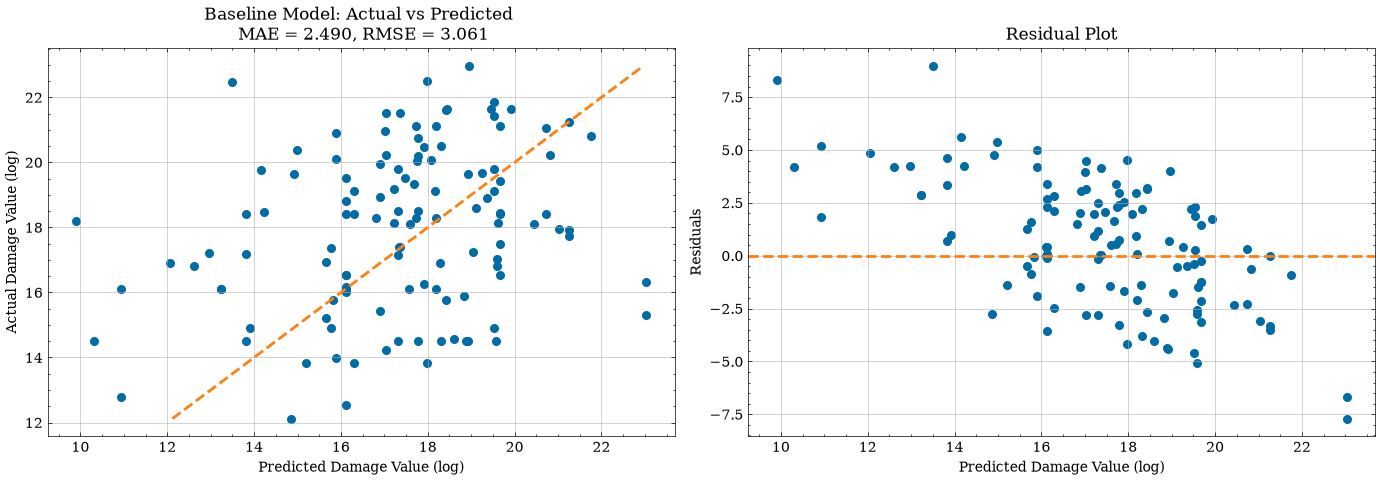

In [7]:
# 4. Visualize the deviations of the baseline model predictions from the true values
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# ---- YOUR CODE GOES HERE (START) ---
# Plot 1: x: predictions, y: true values
axes[0].scatter(y_pred, y_test, s=30, color=defined_colors[0])
# line for perfect predictions
axes[0].plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()],c=defined_colors[1], lw=2, linestyle='--')
# plot labels
axes[0].set_xlabel('Predicted Damage Value (log)')
axes[0].set_ylabel('Actual Damage Value (log)')
axes[0].set_title(f'Baseline Model: Actual vs Predicted \n MAE = {baseline_mae:.3f}, RMSE = {baseline_rmse:.3f}')

# Plot 2: x: predictions, y: residuals
residuals = y_test - y_pred
axes[1].scatter(y_pred, residuals, s=30)
# line for perfect predictions
axes[1].axhline(y=0, color=defined_colors[1], linestyle='--', lw=2)
# plot labels
axes[1].set_xlabel('Predicted Damage Value (log)')
axes[1].set_ylabel('Residuals')
axes[1].set_title('Residual Plot')
# --- YOUR CODE GOES HERE (END) ---

plt.tight_layout()
plt.show()

4. Evaluation of the performance in your own words

On the log scale, the charts show how well the model captures relative proportional changes rather than exact dollar differences. Proportional accuracy (getting the right order of magnitude) is often more meaningful than exact numeric accuracy.

An MAE of 2.5 indicates that the model predictions deviate, on average, by about 2.5 log‑units, i.e., the predictions are about e²·⁵ ≈ 12 times too high or too low.

## **TASK: Rolling Window Approach for Retraining**

Now we know that our baseline model struggles with a lot of data points. While we still do not know whether the performance loss stems from concept drift, we could guess that something is happening with the target variable such that outdated data is skewing the more recent predictions of our model. 

Implement a "blind" drift detection method that trains on the past k years and evaluates on the next year, rolling forward through time. This simulates real-world scenarios where models are periodically retrained.

Complete the following steps by replacing the ``None`` placeholders with the correct values and variables:
1. Derive the test and train sets based on a rolling window of 15 years
2. Train a DecisionTreeRegressor and calculate performance metrics
3. Visualize performance over time and compare it to the baseline model

In [8]:
# train on a rolling window of past 15 years
window_size = 15

# Prepare results storage
results_blind = []

# Get unique years in order
unique_years = sorted(df_model["Year"].unique())

In [9]:
# Rolling window approach
# for each year after the initial window
for i in range(window_size, len(unique_years)):
    
  # (1.) Derive the test and train sets based on a rolling window of years
  # ---- YOUR CODE GOES HERE (START) ---
  # Define train and test years: the test year is the current year in the loop, the train years are the previous 'window_size' years
  test_year = unique_years[i]
  train_years = unique_years[i-window_size:i]
  # Create masks for train and test sets (a mask is a boolean array indicating which rows to select)
  train_mask = df_model["Year"].isin(train_years)
  test_mask = df_model["Year"] == test_year
  # Create train and test sets based on the masks
  X_train = df_model[train_mask][[f + " (log)" for f in features]]
  y_train = df_model[train_mask][target + " (log)"]
  X_test = df_model[test_mask][[f + " (log)" for f in features]]
  y_test = df_model[test_mask][target + " (log)"]
  # --- YOUR CODE GOES HERE (END) ---
    
  # (2.) Train a DecisionTreeRegressor and calculate performance metrics
  # ---- YOUR CODE GOES HERE (START) ---
  # Instantiate, fit, and predict with the model
  model = DecisionTreeRegressor(max_depth=3)
  model.fit(X_train, y_train)
  y_pred = model.predict(X_test)
  # Evaluate the model performance
  r2 = r2_score(y_test, y_pred)
  mae = mean_absolute_error(y_test, y_pred)
  rmse = np.sqrt(mean_squared_error(y_test, y_pred))
  # --- YOUR CODE GOES HERE (END) ---
    
  # Store results
  results_blind.append({
    'Test_Year': test_year,
    'Train_Years': f"{train_years[0]}-{train_years[-1]}",
    'Train_Size': len(X_train),
    'Test_Size': len(X_test),
    'R2': r2,
    'MAE': mae,
    'RMSE': rmse
  })

results_blind_df = pd.DataFrame(results_blind)

print(f"Average Performance:")
print(f"  MAE: {results_blind_df['MAE'].mean():.4f} (±{results_blind_df['MAE'].std():.4f}), baseline: {baseline_mae:.4f}")
print(f"  RMSE: {results_blind_df['RMSE'].mean():.4f} (±{results_blind_df['RMSE'].std():.4f}), baseline: {baseline_rmse:.4f}")

Average Performance:
  MAE: 1.8752 (±0.6463), baseline: 2.4900
  RMSE: 2.2590 (±0.7443), baseline: 3.0611


e:\Programme\conda\envs\AAI\Lib\site-packages\sklearn\metrics\_regression.py:1295: UndefinedMetricWarning: R^2 score is not well-defined with less than two samples.
  warnings.warn(msg, UndefinedMetricWarning)


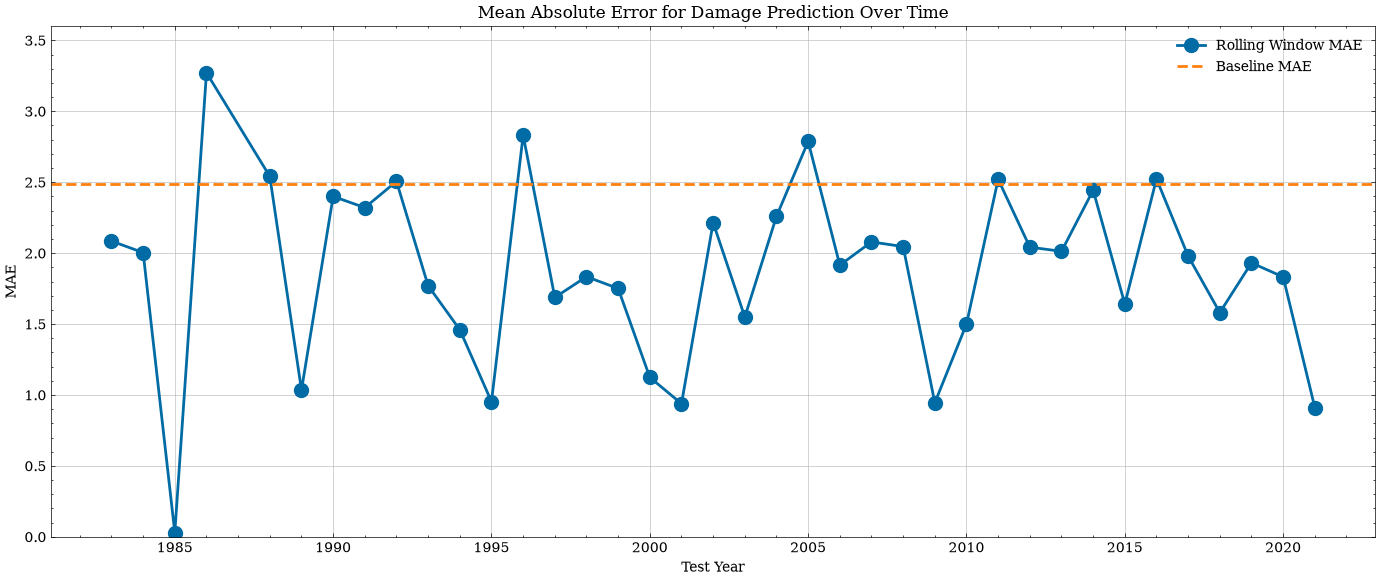

In [10]:
# (3.) Visualize performance over time and compare it to the baseline model
# ---- YOUR CODE GOES HERE (START) ---
# x: Test Year, y: MAE of rolling window model
plt.plot(results_blind_df['Test_Year'], results_blind_df['MAE'], 
      marker='o',markersize=10, linewidth=2, color=defined_colors[0], label='Rolling Window MAE')
# baseline MAE of the initial model
plt.axhline(y=baseline_mae, color=defined_colors[1], linestyle='--', lw=2, label='Baseline MAE')
# --- YOUR CODE GOES HERE (END) ---

# plot formatting
plt.xlabel('Test Year')
plt.ylabel('MAE')
plt.title('Mean Absolute Error for Damage Prediction Over Time')
plt.legend()
plt.ylim(0, max(results_blind_df['MAE'].max(), baseline_mae) * 1.1)

plt.tight_layout()
plt.show()

By "blindly" removing outdated data from the training window, we can achieve better performance than for the baseline model that used all training data for almost all test years. So, apparently something about the target variable (damage) changed over the course of the years that makes old data obsolete.